In [1]:
import pandas as pd
import sqlite3


In [4]:
import os
import pandas as pd
import sqlite3

# Create a database connection
conn = sqlite3.connect(':memory:')

# List of main CSV datasets in /content/
csv_files = [
    'sod_revenue.csv',
    'sod_battle_short.csv',
    'sod_register.csv',
    'sod_adrevenue.csv',
    'sod_session_start.csv'
]


In [5]:
query_session_base="""WITH session_base AS (
   SELECT
       user_id,
       DATE(event_time) AS stat_date,
       COUNT(DISTINCT user_session_id) AS daily_sessions,
       SUM(event_session_length) AS total_session_length,
       MAX(CAST(user_payer_user AS INT)) AS user_payer_user,
       MAX(user_country) AS user_country,
       MAX(user_device_platform) AS user_device_platform,
       MAX(CAST(user_marketing_user AS INT)) AS user_marketing_user,
       MIN(user_install_time) AS user_install_time,
       MAX(user_cumulative_iap_revenue) AS cumulative_iap_revenue,
       MAX(user_cumulative_iap_payments) AS cumulative_iap_payments,
       MAX(user_point_in_lifetime) AS user_point_in_lifetime
   FROM sod_session_start
   GROUP BY 1, 2
),

revenue AS (
   SELECT
       user_id,
       DATE(event_time) AS stat_date,
       SUM(event_revenue_gross_usd) AS daily_iap_revenue,
       COUNT(*) AS daily_iap_transactions
   FROM sod_revenue
   GROUP BY 1, 2
),

battle AS (
   SELECT
       user_id,
       DATE(event_time) AS stat_date,
       COUNT(*) AS daily_battles,
       COUNT(CASE WHEN LOWER(event_battle_result) LIKE '%win%'  THEN 1 END) AS daily_battle_wins,
       COUNT(CASE WHEN LOWER(event_battle_result) LIKE '%loss%' THEN 1 END) AS daily_battle_losses,
       AVG(event_battle_duration) AS avg_battle_duration,
       COUNT(DISTINCT custom_battle_type) AS battle_types_played,
       COUNT(DISTINCT custom_map_id) AS maps_played,
       MAX(user_rank) AS user_rank
   FROM sod_battle_short
   GROUP BY 1, 2
),

ad_revenue AS (
   SELECT
       user_id,
       DATE(event_time) AS stat_date,
       SUM(event_revenue_gross_usd) AS daily_ad_revenue,
       COUNT(*) AS daily_ad_events
   FROM sod_adrevenue
   GROUP BY 1, 2
),

user_day AS (
   SELECT
       s.user_id,
       s.stat_date,
       s.user_country,
       s.user_device_platform,
       s.user_install_time,
       s.user_point_in_lifetime,

       CASE WHEN s.user_payer_user = 1 THEN 'Payer' ELSE 'Non-Payer' END AS payer_status,
       CASE WHEN s.user_marketing_user = 1 THEN 'Paid' ELSE 'Organic' END AS marketing_type,

       CASE
           WHEN b.user_rank BETWEEN 1 AND 20 THEN 'Early'
           WHEN b.user_rank BETWEEN 21 AND 100 THEN 'Mid'
           WHEN b.user_rank > 100 THEN 'Elder'
           ELSE 'Unknown'
       END AS player_segment,

       COALESCE(s.daily_sessions, 0) AS daily_sessions,
       COALESCE(s.total_session_length, 0) AS total_session_length,

       COALESCE(v.daily_iap_revenue, 0) AS daily_iap_revenue,
       COALESCE(v.daily_iap_transactions, 0) AS daily_iap_transactions,

       COALESCE(a.daily_ad_revenue, 0) AS daily_ad_revenue,
       COALESCE(a.daily_ad_events, 0) AS daily_ad_events,

       COALESCE(v.daily_iap_revenue, 0)
           + COALESCE(a.daily_ad_revenue, 0) AS daily_total_revenue,

       COALESCE(b.daily_battles, 0) AS daily_battles,
       COALESCE(b.daily_battle_wins, 0) AS daily_battle_wins,
       COALESCE(b.daily_battle_losses, 0) AS daily_battle_losses,

       b.avg_battle_duration

   FROM session_base s
   LEFT JOIN revenue v
       ON s.user_id = v.user_id
       AND s.stat_date = v.stat_date
   LEFT JOIN battle b
       ON s.user_id = b.user_id
       AND s.stat_date = b.stat_date
   LEFT JOIN ad_revenue a
       ON s.user_id = a.user_id
       AND s.stat_date = a.stat_date
)

SELECT
   stat_date,
   user_country,
   user_device_platform,
   payer_status,
   marketing_type,
   player_segment,

   COUNT(DISTINCT user_id) AS dau,
   COUNT(DISTINCT CASE WHEN daily_iap_transactions > 0 THEN user_id END) AS paying_users,

   SUM(daily_sessions)         AS total_sessions,
   SUM(total_session_length)   AS total_session_length,

   SUM(daily_iap_revenue)      AS iap_revenue,
   SUM(daily_ad_revenue)       AS ad_revenue,
   SUM(daily_total_revenue)    AS total_revenue,
   SUM(daily_iap_transactions) AS iap_transactions,
   SUM(daily_ad_events)        AS ads_watched,

   SUM(daily_battles)          AS total_battles,
   SUM(daily_battle_wins)      AS total_battle_wins,
   SUM(daily_battle_losses)    AS total_battle_losses,
   SUM(daily_battles * COALESCE(avg_battle_duration, 0)) AS total_battle_duration

FROM user_day
GROUP BY
   stat_date,
   user_country,
   user_device_platform,
   payer_status,
   marketing_type,
   player_segment;


"""

In [13]:
for file in csv_files:
    table_name = file.replace('.csv', '')
    df = pd.read_csv(f'/content/{file}')
    df.to_sql(table_name, conn, if_exists='replace', index=False)

#  display the results
daily_player_summary = pd.read_sql_query(query_session_base, conn)
display(daily_player_summary.head(100))

,stat_date,user_country,user_device_platform,payer_status,marketing_type,player_segment,dau,paying_users,total_sessions,total_session_length,iap_revenue,ad_revenue,total_revenue,iap_transactions,ads_watched,total_battles,total_battle_wins,total_battle_losses,total_battle_duration
0,2020-01-01,None,Android,Non-Payer,Organic,Early,7,0,22,23992719,0.00,0.3323,0.3323,0,39,46,38,8,7446.0
1,2020-01-01,None,Android,Non-Payer,Organic,Mid,1,0,5,2384894,0.00,0.0611,0.0611,0,6,2,1,1,395.0
2,2020-01-01,None,Android,Non-Payer,Organic,Unknown,4,0,6,2556506,0.00,0.0243,0.0243,0,3,0,0,0,0.0
3,2020-01-01,None,Android,Non-Payer,Paid,Early,4,0,12,12565631,0.00,0.0056,0.0056,0,7,20,17,3,3291.0
4,2020-01-01,None,Android,Non-Payer,Paid,Unknown,1,0,1,2677581,0.00,0.0028,0.0028,0,2,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2020-01-01,AU,iOS,Non-Payer,Organic,Unknown,37,0,51,25405256,0.00,0.1275,0.1275,0,26,0,0,0,0.0
96,2020-01-01,AU,iOS,Non-Payer,Paid,Early,12,0,36,44979353,0.00,0.8844,0.8844,0,37,75,57,18,11982.0
97,2020-01-01,AU,iOS,Non-Payer,Paid,Mid,6,0,22,12338407,0.00,0.0102,0.0102,0,2,21,18,3,2684.0
98,2020-01-01,AU,iOS,Non-Payer,Paid,Unknown,10,0,18,8051245,0.00,0.0204,0.0204,0,4,0,0,0,0.0


In [10]:
from google.colab import files

# Save the aggregated dataframe to a CSV file
output_filename = 'daily_player_summary.csv'
daily_player_summary.to_csv(output_filename, index=False)
print(f"Saved dataset to {output_filename}.")

# Download the file to your local computer
files.download(output_filename)

Saved dataset to daily_player_summary.csv.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
retention="""
WITH cohort AS (
    -- one row per user: install date + attributes
    SELECT
        user_id,
        DATE(MIN(user_install_time)) AS install_date,
        MAX(user_country)            AS user_country,
        MAX(user_device_platform)    AS user_device_platform,
        CASE WHEN MAX(CAST(user_marketing_user AS INT)) = 1
             THEN 'Paid' ELSE 'Organic' END AS marketing_type
    FROM sod_session_start
    WHERE user_install_time IS NOT NULL
    GROUP BY user_id
),

user_flags AS (
    -- one row per user: did they play on day 1 / 3 / 7?
    SELECT
        user_id,
        MAX(CASE WHEN CAST(user_point_in_lifetime AS INT) = 1 THEN 1 ELSE 0 END) AS active_d1,
        MAX(CASE WHEN CAST(user_point_in_lifetime AS INT) = 3 THEN 1 ELSE 0 END) AS active_d3,
        MAX(CASE WHEN CAST(user_point_in_lifetime AS INT) = 7 THEN 1 ELSE 0 END) AS active_d7
    FROM sod_session_start
    WHERE user_point_in_lifetime IS NOT NULL
    GROUP BY user_id
)

SELECT
    c.install_date,
    c.user_country,
    c.user_device_platform,
    c.marketing_type,

    -- denominator
    COUNT(DISTINCT c.user_id) AS installs,

    -- numerators
    COUNT(DISTINCT CASE WHEN f.active_d1 = 1 THEN c.user_id END) AS d1_retained,
    COUNT(DISTINCT CASE WHEN f.active_d3 = 1 THEN c.user_id END) AS d3_retained,
    COUNT(DISTINCT CASE WHEN f.active_d7 = 1 THEN c.user_id END) AS d7_retained,

    -- denominators restricted to cohorts old enough to have reached day N
    COUNT(DISTINCT CASE WHEN c.install_date + 1 <= CURRENT_DATE THEN c.user_id END) AS d1_eligible_installs,
    COUNT(DISTINCT CASE WHEN c.install_date + 3 <= CURRENT_DATE THEN c.user_id END) AS d3_eligible_installs,
    COUNT(DISTINCT CASE WHEN c.install_date + 7 <= CURRENT_DATE THEN c.user_id END) AS d7_eligible_installs

FROM cohort c
LEFT JOIN user_flags f
    ON c.user_id = f.user_id
GROUP BY
    c.install_date,
    c.user_country,
    c.user_device_platform,
    c.marketing_type;
 """

In [15]:
for file in csv_files:
    table_name = file.replace('.csv', '')
    df = pd.read_csv(f'/content/{file}')
    df.to_sql(table_name, conn, if_exists='replace', index=False)

# Run the query and display the results
retention = pd.read_sql_query(retention, conn)
display(retention.head(100))

,install_date,user_country,user_device_platform,marketing_type,installs,d1_retained,d3_retained,d7_retained,d1_eligible_installs,d3_eligible_installs,d7_eligible_installs
0,2016-11-03,PH,iOS,Paid,1,0,0,0,1,1,1
1,2016-11-03,US,iOS,Organic,1,0,0,0,1,1,1
2,2016-11-04,PH,iOS,Organic,1,0,0,0,1,1,1
3,2016-11-04,PH,iOS,Paid,2,0,0,0,2,2,2
4,2016-11-05,PH,iOS,Paid,1,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...
95,2017-03-12,PH,Android,Paid,1,0,0,0,1,1,1
96,2017-03-13,CA,iOS,Paid,1,0,0,0,1,1,1
97,2017-03-13,ID,Android,Organic,1,0,0,0,1,1,1
98,2017-03-14,CA,iOS,Paid,1,0,0,0,1,1,1


In [16]:
from google.colab import files

# Save the aggregated dataframe to a CSV file
output_filename = 'Retention.csv'
retention.to_csv(output_filename, index=False)
print(f"Saved dataset to {output_filename}.")

# Download the file to your local computer
files.download(output_filename)

Saved dataset to Retention.csv.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import pandas as pd
import numpy as np

# 1. Load the battles dataset
battle_df = pd.read_csv('/content/sod_battle_short.csv', low_memory=False)

# 2. Filter specifically for 'campaign' battles
campaign_df = battle_df[battle_df['custom_battle_type'].str.lower() == 'campaign'].copy()

print(f"Total Campaign Battles: {len(campaign_df)}")
print(f"Unique Players in Campaign: {campaign_df['user_id'].nunique()}")

# 3. Clean and map results to Win/Loss
campaign_df['is_win'] = campaign_df['event_battle_result'].str.lower().str.contains('win').astype(int)

# 4. Analyze difficulty spikes (Win rate by map/level)
map_stats = campaign_df.groupby('custom_map_id').agg(
    total_battles=('event_battle_result', 'count'),
    win_rate=('is_win', 'mean'),
    avg_duration=('event_battle_duration', 'mean')
).reset_index()

# Filter out maps with very few battles to get stable stats
significant_maps = map_stats[map_stats['total_battles'] >= 10].sort_values(by='win_rate')

print("\n=== Top 5 Hardest Campaign Maps (Lowest Win Rates) ===")
print(significant_maps.head(5).to_string(index=False))

print("\n=== Top 5 Easiest Campaign Maps (Highest Win Rates) ===")
print(significant_maps.tail(5).sort_values(by='win_rate', ascending=False).to_string(index=False))

# 5. Analyze player ranks playing campaign
rank_stats = campaign_df.groupby('user_rank').agg(
    battles=('event_battle_result', 'count'),
    win_rate=('is_win', 'mean')
).reset_index().sort_values(by='user_rank')

print("\n=== Campaign Performance by Player Rank (First 20 Ranks) ===")
print(rank_stats.head(20).to_string(index=False))

# 6. Overall campaign summary insights
overall_win_rate = campaign_df['is_win'].mean()
avg_battle_length = campaign_df['event_battle_duration'].mean()
print(f"\n=== Overall Metrics ===")
print(f"Overall Campaign Win Rate: {overall_win_rate:.2%}")
print(f"Average Campaign Battle Duration: {avg_battle_length:.1f} seconds")

Total Campaign Battles: 1193175
Unique Players in Campaign: 76293

=== Top 5 Hardest Campaign Maps (Lowest Win Rates) ===
 custom_map_id  total_battles  win_rate  avg_duration
         706.0           6955  0.171963    129.529260
         703.0           9329  0.236896    102.367992
         502.0          37338  0.462987    136.111174
         705.0           4388  0.505469    151.252051
         707.0           3206  0.528696    143.733936

=== Top 5 Easiest Campaign Maps (Highest Win Rates) ===
 custom_map_id  total_battles  win_rate  avg_duration
         408.0          53557  0.967586    195.549191
         406.0          20549  0.951093    190.816925
         307.0          30154  0.943755    181.180440
         506.0          12969  0.932146    182.573213
         206.0          45817  0.929960    201.349324

=== Campaign Performance by Player Rank (First 20 Ranks) ===
 user_rank  battles  win_rate
       1.0    32720  0.874664
       2.0    65773  0.877761
       3.0    59943  

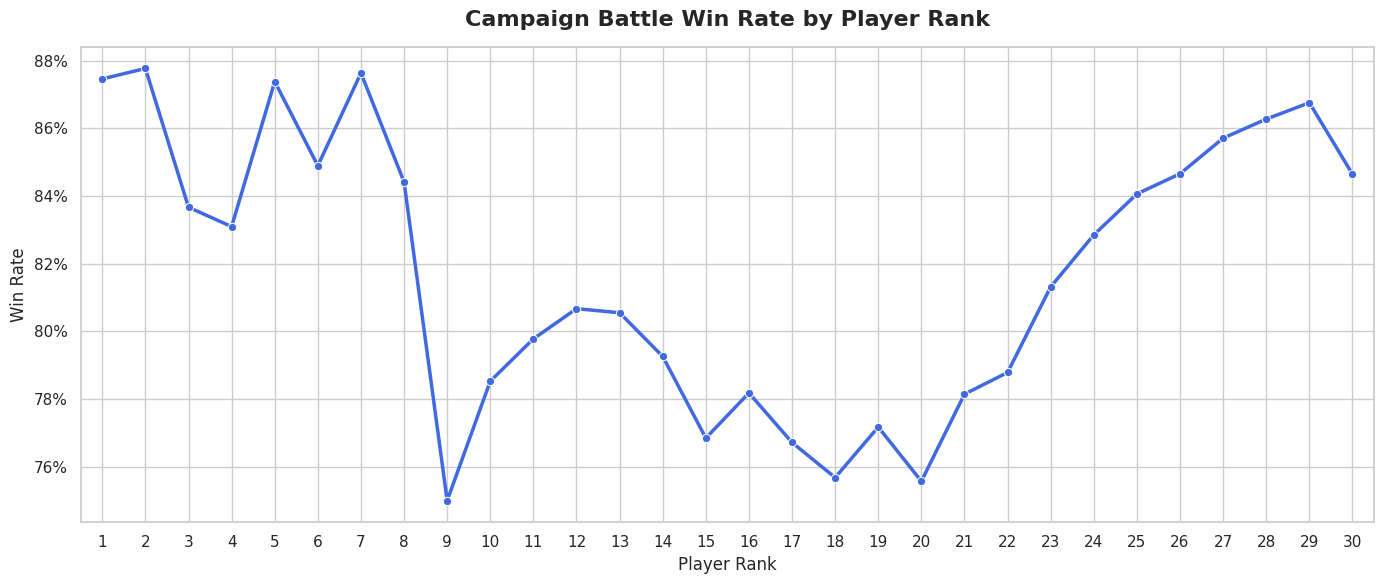

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Plot win rate over rank (pure line plot with markers)
sns.lineplot(data=rank_stats, x='user_rank', y='win_rate', marker='o', color='royalblue', linewidth=2.5)

# Titles and Labels
plt.title('Campaign Battle Win Rate by Player Rank', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Player Rank', fontsize=12)
plt.ylabel('Win Rate', fontsize=12)

# Format y-axis as percentage
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))

# Set x-ticks to display every integer rank clearly up to Rank 30
plt.xticks(range(1, 31))
plt.xlim(0.5, 30.5)

plt.tight_layout()
plt.show()